<a href="https://colab.research.google.com/github/jsmak/mytransformer/blob/main/notebooks/04_Multihead_attention_step1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 트랜스포머의 어텐션 메커니즘 (Attention is All you Need, Figure 2) 설명

이 노트북은 ["Attention Is All You Need"](https://arxiv.org/abs/1706.03762) 논문의 핵심 메커니즘인 "Scaled Dot-Product Attention"과   
"Multi-Head Attention"을 PyTorch로 구현하고 그 동작을 시각적으로 설명합니다.  

### 1. Scaled Dot-Product Attention (`ScaledDotProductAttention` 클래스)

논문의 Figure 2(왼쪽)에 해당하는 부분입니다.   
입력으로 Query (Q), Key (K), Value (V)를 받아서 어텐션 스코어를 계산하고, 스케일링 후 소프트맥스를 적용하여 어텐션 가중치를 얻습니다.   
이 가중치를 Value에 곱하여 최종적인 컨텍스트 벡터를 생성합니다.  

- **MatMul (Q와 K 트랜스포즈의 곱)**: 쿼리가 키와 얼마나 관련이 있는지를 측정합니다.  
- **Scale (루트 d_k로 나누기)**: 내적 값이 너무 커져 소프트맥스 함수의 기울기가 작아지는 것을 방지합니다.  
- **SoftMax**: 각 Value에 대한 확률 분포를 만들어 줍니다.  
- **MatMul (어텐션 가중치와 V의 곱)**: 이 확률 분포를 바탕으로 Value들을 가중 평균하여 최종 출력(컨텍스트 벡터)을 만듭니다.  
- **(Optional) Mask**: 특정 토큰(예: 패딩 토큰, 미래 토큰)이 어텐션에 영향을 주지 않도록 마스킹합니다.  

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ============================================================
# 논문 Figure 2 (왼쪽) - Scaled Dot-Product Attention
# Attention(Q,K,V) = softmax(QK^T / √d_k) V
# ============================================================
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_head):
        super().__init__()
        self.d_head = d_head

    def forward(self, Q, K, V, attn_mask=None):
        # MatMul: Q @ K^T
        attention_scores = Q @ K.transpose(-2, -1)

        # (Optional) Mask: 미래 토큰을 가리기 위한 마스크
        if attn_mask is not None:
            attention_scores = attention_scores.masked_fill(attn_mask == 0, float("-inf"))

        # Scale + SoftMax
        attention_weights = F.softmax(attention_scores / math.sqrt(self.d_head), dim=-1)

        # MatMul: attention_weights @ V
        context_vector = attention_weights @ V
        return context_vector


### 2. Multi-Head Attention (`MultiHeadAttention` 클래스)

논문의 Figure 2(오른쪽)에 해당하는 부분입니다. 'Attention' 메커니즘을 여러 번 병렬적으로 수행하여 다양한 관점에서 정보를 포착할 수 있도록 합니다.   
각 "헤드"는 입력 Q, K, V에 대해 독립적인 선형 변환(`W_q`, `W_k`, `W_v`)을 적용한 후 `ScaledDotProductAttention`을 수행합니다.   
이렇게 얻은 여러 헤드의 출력을 `Concat` (연결)한 다음, 최종적으로 하나의 선형 변환(`W_o`)을 거쳐 출력됩니다.  
$$MultiHead(Q,K,V) = Concat(head_1, ..., head_h) W_O$$

$$where\ head_i = Attention(Q W_{q_i}, K W_{k_i}, V W_{v_i})$$

- **Linear (각 헤드별)**: Q, K, V를 여러 개의 작은 차원(`d_head`)으로 투영합니다. 이를 통해 모델이 다양한 표현 공간에서 어텐션을 학습할 수 있습니다.
- **h개의 Scaled Dot-Product Attention 병렬 수행**: 각 헤드에서 독립적으로 어텐션을 계산합니다.
- **Concat**: 각 헤드의 결과를 하나로 연결하여 원래 `d_model` 차원으로 복원합니다.
- **Linear (최종 출력)**: 연결된 결과를 다시 한 번 선형 변환하여 최종 출력을 생성합니다.

이러한 멀티 헤드 어텐션은 모델이 문장 내의 서로 다른 위치에서 정보를 공동으로 집중할 수 있도록 하여, 문맥 정보를 더 풍부하게 이해하게 합니다.

In [5]:
# ============================================================
# 논문 Figure 2 (오른쪽) - Multi-Head Attention
# ============================================================
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads  # d_k = d_v = d_model / h

        # --- head별 Linear (논문 그림의 "Linear" 3개) ---
        self.W_q = nn.ParameterList()
        self.W_k = nn.ParameterList()
        self.W_v = nn.ParameterList()
        self.attentions = nn.ModuleList()

        for _ in range(num_heads):
            self.W_q.append(nn.Parameter(torch.randn(d_model, self.d_head)))  # W_q_i
            self.W_k.append(nn.Parameter(torch.randn(d_model, self.d_head)))  # W_k_i
            self.W_v.append(nn.Parameter(torch.randn(d_model, self.d_head)))  # W_v_i
            self.attentions.append(ScaledDotProductAttention(self.d_head))

        # --- 논문 그림의 "Linear" (Concat 뒤) ---
        self.W_o = nn.Parameter(torch.randn(d_model, d_model))  # W_O

    def forward(self, xq, xk, xv, attn_mask=None):
        head_outputs = []

        for i in range(self.num_heads):
            # 각 head별 Linear projection
            Q = xq @ self.W_q[i]  # (batch, seq, d_model) → (batch, seq, d_head)
            K = xk @ self.W_k[i]
            V = xv @ self.W_v[i]

            # Scaled Dot-Product Attention
            head_output = self.attentions[i](Q, K, V, attn_mask)
            head_outputs.append(head_output)

        # Concat: 모든 head 출력을 이어붙임 → (batch, seq, d_model)
        context = torch.cat(head_outputs, dim=-1)

        # 마지막 Linear: Concat 결과에 W_O를 곱함
        out = context @ self.W_o
        return out

## 샘플 실행 결과 설명

위 코드는 `d_model=9`, `num_heads=3`으로 설정하여 `MultiHeadAttention` 모듈을 생성하고 실행하는 예시입니다.   
`d_head`는 `d_model / num_heads`이므로 `9 / 3 = 3`이 됩니다.   
이는 각 어텐션 헤드가 3차원의 Query, Key, Value를 처리한다는 의미입니다.

**입력 `x`:**
- `x`의 형태는 `(batch_size, seq_len, d_model)`인 `(1, 4, 9)`입니다.   
이는 1개의 배치에 4개의 토큰(단어)이 있고, 각 토큰은 9차원의 벡터로 표현됨을 의미합니다.

**`MultiHeadAttention` 실행 과정:**

1. **각 Head별 선형 변환 및 Scaled Dot-Product Attention:**
   - `mha.W_q[i]`, `mha.W_k[i]`, `mha.W_v[i]`는 각각 `(d_model, d_head)` 형태인 `(9, 3)`의 가중치 행렬입니다.
   - 입력 `x` (`(1, 4, 9)`)와 이 가중치 행렬들을 곱하여 각 헤드별 Q, K, V를 생성합니다. 예를 들어, `Q = x @ mha.W_q[i]`의 결과는 `(1, 4, 3)` 형태를 가집니다. 즉, 각 토큰이 3차원의 Q, K, V 벡터로 투영됩니다.
   - 이 `(1, 4, 3)` 형태의 Q, K, V는 `ScaledDotProductAttention`에 입력되어 `head_output`을 생성합니다. `head_output` 또한 `(1, 4, 3)` 형태를 가집니다.

2. **`Concat` (연결):**
   - 3개의 헤드에서 나온 `head_output` (각각 `(1, 4, 3)`)이 `dim=-1` (마지막 차원, 즉 `d_head` 차원)을 기준으로 연결됩니다.
   - 연결 결과 `context`의 형태는 `(batch, seq_len, d_head × num_heads)`인 `(1, 4, 3 × 3) = (1, 4, 9)`가 됩니다. 이는 원래 `d_model` 차원과 동일합니다.

3. **최종 선형 변환:**
   - `context` (`(1, 4, 9)`)는 최종 가중치 행렬 `mha.W_o` (`(d_model, d_model)`인 `(9, 9)`)와 곱해집니다.
   - 최종 출력 `output`의 형태는 `(batch, seq_len, d_model)`인 `(1, 4, 9)`가 됩니다. 이는 입력 `x`와 동일한 형태를 가집니다.

이러한 과정을 통해 `MultiHeadAttention`은 입력 시퀀스의 각 토큰에 대해 여러 개의 어텐션 헤드를 통해 다양한 관계 정보를 추출하고, 이를 통합하여 최종 출력을 생성함을 확인할 수 있습니다.

In [4]:
#============================================================
# 샘플 실행
# ============================================================
d_model = 9
num_heads = 3
d_head = d_model // num_heads  # 3

# 4개 토큰으로 구성된 문장 1개 (batch=1)
seq_len = 4
batch_size = 1

# 입력: (batch, seq_len, d_model) = (1, 4, 9)
x = torch.randn(batch_size, seq_len, d_model)

print("=" * 50)
print("설정값")
print(f"  d_model    = {d_model}")
print(f"  num_heads  = {num_heads}")
print(f"  d_head     = {d_head} (= d_model / num_heads)")
print(f"  seq_len    = {seq_len}")
print(f"  batch_size = {batch_size}")
print("=" * 50)

print(f"\n입력 x shape: {x.shape}")
print(f"입력 x:\n{x}")

# Multi-Head Attention 생성 및 실행
# Self-Attention이므로 xq = xk = xv = x
mha = MultiHeadAttention(d_model, num_heads)
output = mha(xq=x, xk=x, xv=x)

print(f"\n출력 shape: {output.shape}")
print(f"출력:\n{output}")

# 각 head의 중간 과정 확인
print("\n" + "=" * 50)
print("각 head별 중간 과정")
print("=" * 50)

for i in range(num_heads):
    Q = x @ mha.W_q[i]
    K = x @ mha.W_k[i]
    V = x @ mha.W_v[i]
    print(f"\n--- Head {i} ---")
    print(f"  W_q[{i}] shape: {mha.W_q[i].shape}  (d_model, d_head) = ({d_model}, {d_head})")
    print(f"  Q shape:     {Q.shape}  (batch, seq_len, d_head) = ({batch_size}, {seq_len}, {d_head})")
    print(f"  K shape:     {K.shape}")
    print(f"  V shape:     {V.shape}")

    head_output = mha.attentions[i](Q, K, V)
    print(f"  head output: {head_output.shape}")

# Concat 결과 확인
print(f"\nConcat 후 shape: ({batch_size}, {seq_len}, {d_head} × {num_heads}) = ({batch_size}, {seq_len}, {d_model})")
print(f"W_o shape:       {mha.W_o.shape}  (d_model, d_model) = ({d_model}, {d_model})")
print(f"최종 출력 shape: {output.shape}  (batch, seq_len, d_model)")

설정값
  d_model    = 9
  num_heads  = 3
  d_head     = 3 (= d_model / num_heads)
  seq_len    = 4
  batch_size = 1

입력 x shape: torch.Size([1, 4, 9])
입력 x:
tensor([[[-0.4395,  1.1418, -0.7251, -1.1927,  1.7353,  0.0251, -2.3270,
          -1.4008, -0.6526],
         [ 0.0749, -0.3668,  1.7206,  0.2586,  0.4087, -1.0122,  0.6645,
          -0.1904, -1.1226],
         [-2.6472, -0.3863,  1.9688,  0.5275, -1.4913,  0.0104,  0.4023,
          -1.5462, -0.1397],
         [ 0.0305,  1.2567,  0.2807,  0.1989,  0.4244,  0.9789, -0.1981,
           0.4866,  0.1708]]])

출력 shape: torch.Size([1, 4, 9])
출력:
tensor([[[  3.2834, -10.0780,   2.6424,  11.5887,  13.9697, -37.2357,  27.8574,
          -12.5189,  -2.0772],
         [ -4.5166,  -5.4064, -17.2081,   2.7183,  -2.1841,  -8.3517,  18.4492,
          -10.1913,  -9.8215],
         [ -5.4072,  -9.9579,  -3.5411,  15.8874,   2.0045, -21.7631,  26.3333,
          -15.8927,   0.7914],
         [ -1.3310,  -4.5970,   0.7611,  -2.5784,  -2.7973,  -1.03

## 입력 및 출력 텐서 시각화

`MultiHeadAttention` 모듈을 통과하기 전후의 텐서 `x`와 `output`의 값을 시각화하여 변화를 살펴봅니다. 각 행은 시퀀스 내의 한 토큰을 나타내고, 각 열은 해당 토큰의 `d_model` 차원 벡터의 한 요소를 나타냅니다. 히트맵을 통해 값의 분포와 변화를 직관적으로 파악할 수 있습니다.

## 각 Attention Head 출력 및 Concat 결과 시각화

`MultiHeadAttention` 내부에서 각 개별 헤드(H0, H1, H2)가 생성하는 출력과, 이들을 하나로 이어 붙인(`Concat`) `context` 텐서의 값을 시각화합니다. 이를 통해 각 헤드가 어떤 정보를 포착하고 있으며, 이 정보들이 어떻게 결합되는지 상세하게 이해할 수 있습니다.

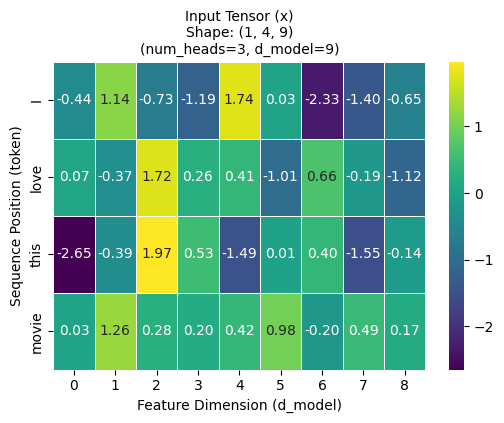

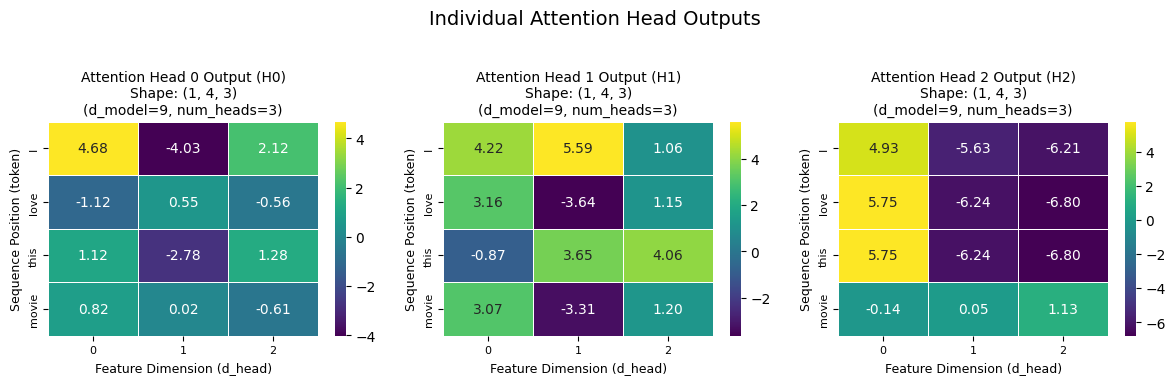

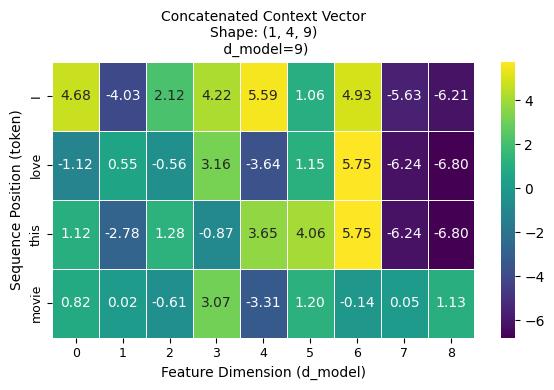

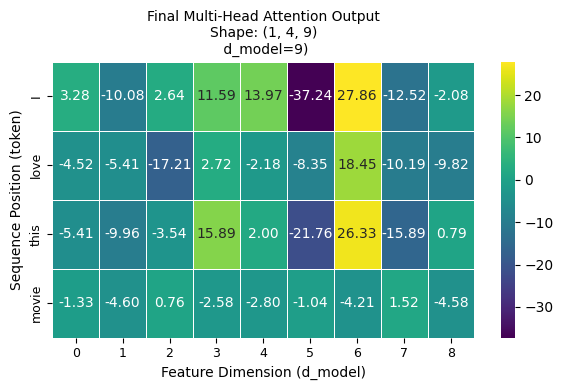

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Re-run the forward pass to capture intermediate head_outputs and context
# (These were local variables in the previous mha.forward call)
# And also ensure 'output_final' is consistent with this run

head_outputs_captured = []
for i in range(mha.num_heads):
    Q_i = x @ mha.W_q[i]
    K_i = x @ mha.W_k[i]
    V_i = x @ mha.W_v[i]
    head_output_i = mha.attentions[i](Q_i, K_i, V_i)
    head_outputs_captured.append(head_output_i)

context_captured = torch.cat(head_outputs_captured, dim=-1);
# Recalculate final output for consistency, assuming mha, x are available
output_final = mha(xq=x, xk=x, xv=x)


# Example text labels for sequence positions
# You can customize these based on your actual data/context
seq_labels = ['I', 'love', 'this', 'movie']

# Input Tensor (x) Visualization
plt.figure(figsize=(6, 4))
sns.heatmap(x.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
plt.title(f'Input Tensor (x)\nShape: ({batch_size}, {seq_len}, {d_model})\n(num_heads={num_heads}, d_model={d_model})', fontsize=10)
plt.xlabel('Feature Dimension (d_model)')
plt.ylabel('Sequence Position (token)')
plt.show()


# -------------------------------------------------------------
# Visualize each head output (H0, H1, H2) horizontally
# -------------------------------------------------------------
plt.figure(figsize=(12, 4)) # Adjusted for horizontal layout of 3 plots

for i, head_output in enumerate(head_outputs_captured):
    plt.subplot(1, mha.num_heads, i + 1) # 1 row, num_heads columns
    sns.heatmap(head_output.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
    plt.title(f'Attention Head {i} Output (H{i})\nShape: ({batch_size}, {seq_len}, {d_head})\n(d_model={d_model}, num_heads={num_heads})', fontsize=10)
    plt.xlabel('Feature Dimension (d_head)', fontsize=9)
    plt.ylabel('Sequence Position (token)', fontsize=9)
    # Adjusting tick label font size
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)

plt.suptitle('Individual Attention Head Outputs', fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()

# -------------------------------------------------------------
# Visualize the concatenated context
# -------------------------------------------------------------
plt.figure(figsize=(6, 4)) # A bit larger for d_model
sns.heatmap(context_captured.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
plt.title(f'Concatenated Context Vector\nShape: ({batch_size}, {seq_len}, {d_model})\n d_model={d_model})', fontsize=10)
plt.xlabel('Feature Dimension (d_model)', fontsize=10)
plt.ylabel('Sequence Position (token)', fontsize=10)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Visualize the final Multi-Head Attention output
# -------------------------------------------------------------
plt.figure(figsize=(6, 4)) # Same size as context for comparison
sns.heatmap(output_final.squeeze().detach().numpy(), cmap='viridis', annot=True, fmt=".2f", linewidths=.5, yticklabels=seq_labels)
plt.title(f'Final Multi-Head Attention Output\nShape: ({batch_size}, {seq_len}, {d_model})\n d_model={d_model})', fontsize=10)
plt.xlabel('Feature Dimension (d_model)', fontsize=10)
plt.ylabel('Sequence Position (token)', fontsize=10)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()